# Part 2: Head-and-Tail Truncation (Member 2)
**CISC7021 NLP, Group 38** | LongBench `multifieldqa_en` | Target LLM: `unsloth/Llama-3.2-3B-Instruct`

**Research focus.** Part 2 keeps the first and last tokens of each document and drops the middle, so the document has about 1/ratio of its tokens (2x and 4x). The instruction and question are never truncated.

**This notebook**
1. Sets up the environment (local or Colab) and reuses code from `shared/` and `part1_uncompressed/`.
2. *(Optional)* Re-runs Part 2 with resume support (`RERUN = True`), kept for Colab disconnections.
3. Loads the Part 2 result files and reports the main metrics.
4. Analyses where the gold answer sits in the original document and whether truncation kept it.
5. Saves ACL-ready PDF figures and tables.

## 1. Configuration

In [5]:
import os, sys, json, subprocess, time
from pathlib import Path

RERUN = False            # True: regenerate Part 2 results with run_truncation.py (needs a GPU)
RATIOS = (2, 4)          # target compression ratios
HEAD_FRAC = 0.5          # share of the kept budget given to the document head
DTYPE = "float16"

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasonche515/CISC7021-Group38.git"
DRIVE_OUT = "/content/drive/MyDrive/cisc7021/results"   # Colab output folder (survives disconnects)
print("Running in Colab:", IN_COLAB, "| RERUN:", RERUN)

Running in Colab: True | RERUN: False


## 2. Environment setup
Only runs in Google Colab: clones the repository, installs the requirements from Part 1, and mounts Google Drive so results survive a disconnection. On a local machine this cell does nothing.

In [2]:
if IN_COLAB:
    if not Path("/content/CISC7021-Group38").exists():
        !git clone {REPO_URL}
    %cd /content/CISC7021-Group38
    !git pull origin main
    !pip -q install -r part1_uncompressed/requirements.txt
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_OUT, exist_ok=True)

Cloning into 'CISC7021-Group38'...
remote: Enumerating objects: 162, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (125/125), done.
remote: Total 162 (delta 72), reused 123 (delta 35), pack-reused 0 (from 0)
Receiving objects: 100% (162/162), 4.44 MiB | 8.43 MiB/s, done.
Resolving deltas: 100% (72/72), done.
/content/CISC7021-Group38
From https://github.com/jasonche515/CISC7021-Group38
 * branch            main       -> FETCH_HEAD
Already up to date.
Mounted at /content/drive


## 3. Project paths and shared imports
**Purpose of reading `shared/` and `part1_uncompressed/`:** Part 2 must be *directly comparable* with the other three parts, so it reuses the same building blocks instead of re-implementing them.

| Imported from | What | Why it matters |
|---|---|---|
| `shared.config` | `MODEL_ID`, `MAX_NEW_TOKENS`, `SAMPLES_PATH` | Same model, greedy decoding, same 150 fixed samples (seed=42) |
| `shared.metrics` | `score`, `mean_metrics` | Same EM / token-F1 definitions |
| `shared.prompt_template` | `render_input_ids` | Same instruction and question wording |
| `part1_uncompressed.run_baseline` | `HFBackend`, `load_samples`, `load_jsonl`, `write_json` | Same model loader and I/O format as the baseline |
| `part2_truncation.run_truncation` | `head_tail_truncate` | The method itself |

In [6]:
def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "shared" / "config.py").exists():
            return p
    raise FileNotFoundError("Run this notebook inside the project repo (shared/config.py not found).")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
HERE = ROOT / "part2_truncation"
FIG_DIR = HERE / "figures"
FIG_DIR.mkdir(exist_ok=True)

from shared.config import MODEL_ID, MAX_NEW_TOKENS, SAMPLES_PATH
from shared.metrics import score, mean_metrics
from shared.prompt_template import render_input_ids
from part1_uncompressed.run_baseline import load_samples, load_jsonl
from part2_truncation.run_truncation import head_tail_truncate

OUT_DIR = Path(DRIVE_OUT) if IN_COLAB else HERE
print("ROOT:", ROOT)
print("MODEL_ID:", MODEL_ID, "| MAX_NEW_TOKENS:", MAX_NEW_TOKENS)
print("Results folder:", OUT_DIR)

ROOT: /content/CISC7021-Group38
MODEL_ID: meta-llama/Llama-3.2-3B-Instruct | MAX_NEW_TOKENS: 64
Results folder: /content/drive/MyDrive/cisc7021/results


## 4. Method: head-and-tail truncation
The document is tokenised; with `budget = round(n / ratio)` tokens, the first `int(budget * head_frac)` tokens and the last `budget - head` tokens are kept and the middle is dropped. Below is a quick demonstration on one sample.

In [8]:
from transformers import AutoTokenizer

MODEL_ID = "unsloth/Llama-3.2-3B-Instruct"   # public mirror; overrides the gated default
print("Using model:", MODEL_ID)

tok = AutoTokenizer.from_pretrained(MODEL_ID)
samples_list = load_samples(SAMPLES_PATH, None)
samples = {s["id"]: s for s in samples_list}
print("Loaded samples:", len(samples_list))

demo = samples_list[0]
for r in RATIOS:
    text, n_orig, n_kept = head_tail_truncate(tok, demo["docs"], r, HEAD_FRAC)
    print(f"ratio {r}x: {n_orig} -> {n_kept} doc tokens ({n_kept / n_orig:.1%} kept)")

Using model: unsloth/Llama-3.2-3B-Instruct


config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Loaded samples: 150
ratio 2x: 8903 -> 4452 doc tokens (50.0% kept)
ratio 4x: 8903 -> 2226 doc tokens (25.0% kept)


## 5. (Optional) Re-run Part 2
Kept from the earlier Colab workflow. `run_truncation.py` writes one JSONL row per sample and **resumes** automatically, so after a disconnection simply run this cell again. Set `RERUN = True` in Section 1 to use it. Requires a GPU.

In [9]:
def run_part2(ratio):
    cmd = [sys.executable, str(HERE / "run_truncation.py"),
           "--ratio", str(ratio), "--dtype", DTYPE, "--model", MODEL_ID,
           "--head-frac", str(HEAD_FRAC), "--out-dir", str(OUT_DIR)]
    env = {**os.environ, "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True"}
    t0 = time.perf_counter()
    subprocess.run(cmd, check=True, cwd=ROOT, env=env)
    print(f"ratio {ratio}x finished in {(time.perf_counter() - t0) / 60:.1f} min")

if RERUN:
    for r in RATIOS:
        run_part2(r)
else:
    print("RERUN is False: skipping generation and reading existing result files.")

RERUN is False: skipping generation and reading existing result files.


## 6. Load results and main metrics
The loader searches the Drive folder (Colab), then `part2_truncation/`, so the same cell works locally and in Colab.

In [10]:
import pandas as pd, numpy as np

def tag(r):
    return f"{r:g}x" + ("" if HEAD_FRAC == 0.5 else f"_h{HEAD_FRAC:g}")

def find_result(r):
    for d in (OUT_DIR, HERE):
        p = d / f"results_member2_{tag(r)}.json"
        if p.exists():
            return p
    raise FileNotFoundError(f"results_member2_{tag(r)}.json not found in {OUT_DIR} or {HERE}")

payloads = {r: json.load(open(find_result(r), encoding="utf-8")) for r in RATIOS}

rows = []
for r, p in payloads.items():
    s = p["summary"]
    rows.append({"Method": f"Head-tail {r}x", "n": s.get("num_samples"),
                 "EM": s.get("mean_em"), "F1": s.get("mean_f1"),
                 "Prompt tokens": s.get("mean_prompt_tokens"),
                 "Doc ratio": s.get("mean_compression_ratio"),
                 "Total latency (s)": s.get("mean_total_latency")})
summary_df = pd.DataFrame(rows).round(4)
summary_df.to_csv(HERE / "part2_summary_table.csv", index=False)
summary_df

,Method,n,EM,F1,Prompt tokens,Doc ratio,Total latency (s)
0,Head-tail 2x,150,0.0733,0.4065,3523.0533,2.0000,5.8221
1,Head-tail 4x,150,0.0667,0.3620,1801.1800,3.9999,3.5463


## 7. Answer-position analysis
**Question:** does head-and-tail truncation work because the answer tends to sit near the start or end of the document, and does it fail when the answer lies in the dropped middle?

**Method.** For each sample we find the gold answer in the *original* document (case-insensitive string match, all occurrences), map it to token positions, and compare it with the kept head and tail ranges:

| Zone | Meaning |
|---|---|
| `kept_head` / `kept_tail` | An answer occurrence lies fully inside the kept head or tail |
| `partial` | An occurrence overlaps a kept region but is cut at the boundary |
| `dropped_middle` | Every occurrence lies in the removed middle |
| `not_found` | No answer string in the document (abstractive answer); excluded from position plots |

In [11]:
def locate_answer(tokenizer, docs, answers, ratio, head_frac, max_occ=50):
    enc = tokenizer(docs, add_special_tokens=False, return_offsets_mapping=True)
    offs = np.array(enc["offset_mapping"])
    n_orig = len(offs)
    starts, ends = offs[:, 0], offs[:, 1]
    budget = max(1, round(n_orig / ratio))
    head_n = int(budget * head_frac)
    tail_n = budget - head_n
    low = docs.lower()

    spans = []
    for a in answers:
        a = a.lower().strip()
        if not a:
            continue
        i = low.find(a)
        while i >= 0 and len(spans) < max_occ:
            spans.append((i, i + len(a)))
            i = low.find(a, i + 1)
    if not spans:
        return {"answer_found": False, "answer_rel_pos": np.nan, "answer_zone": "not_found", "n_orig": n_orig}

    zones = []
    for cs, ce in spans:
        s_tok = int(np.searchsorted(ends, cs, side="right"))
        e_tok = int(np.searchsorted(starts, ce, side="left")) - 1
        e_tok = max(e_tok, s_tok)
        if e_tok < head_n:
            zones.append("kept_head")
        elif s_tok >= n_orig - tail_n:
            zones.append("kept_tail")
        elif s_tok < head_n or e_tok >= n_orig - tail_n:
            zones.append("partial")
        else:
            zones.append("dropped_middle")
    for z in ("kept_head", "kept_tail", "partial", "dropped_middle"):
        if z in zones:
            zone = z
            break
    first_s = int(np.searchsorted(ends, spans[0][0], side="right"))
    return {"answer_found": True, "answer_rel_pos": first_s / max(n_orig, 1),
            "answer_zone": zone, "n_orig": n_orig}

In [12]:
records = []
for r, p in payloads.items():
    for row in p["results"]:
        s = samples[row["id"]]
        info = locate_answer(tok, s["docs"], s["answers"], r, HEAD_FRAC)
        records.append({"ratio": r, "id": row["id"], "f1": row["f1"], "em": row["em"],
                        "prompt_tokens": row["prompt_tokens"], **info})
pos_df = pd.DataFrame(records)
pos_df.to_csv(HERE / "answer_position_analysis.csv", index=False)

zone_order = ["kept_head", "kept_tail", "partial", "dropped_middle", "not_found"]
zone_table = (pos_df.groupby(["ratio", "answer_zone"])
              .agg(n=("f1", "size"), mean_f1=("f1", "mean"), mean_em=("em", "mean"))
              .round(4).reset_index())
print("Answer found in document:", pos_df.groupby("ratio").answer_found.mean().round(3).to_dict())
zone_table

Answer found in document: {2: 0.12, 4: 0.12}


,ratio,answer_zone,n,mean_f1,mean_em
0,2,dropped_middle,5,0.1452,0.0000
1,2,kept_head,12,0.4535,0.2500
2,2,kept_tail,1,0.0526,0.0000
3,2,not_found,132,0.4149,0.0606
4,4,dropped_middle,8,0.0840,0.0000
5,4,kept_head,9,0.5534,0.3333
6,4,kept_tail,1,0.0000,0.0000
7,4,not_found,132,0.3686,0.0530


## 8. Statistics: kept vs dropped
Compares F1 when the answer is **kept** (head or tail) against **dropped** (middle), with bootstrap 95% confidence intervals. Small groups give wide intervals, so always report `n`.

In [14]:
def boot_ci(x, n_boot=5000, seed=42):
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))

def grp(z):
    return {"kept_head": "Kept", "kept_tail": "Kept", "partial": "Partial",
            "dropped_middle": "Dropped"}.get(z)

pos_df["group"] = pos_df.answer_zone.map(grp)
stat_rows = []
for r in RATIOS:
    d = pos_df[pos_df.ratio == r]
    for g in ("Kept", "Partial", "Dropped"):
        x = d[d.group == g].f1.values
        lo, hi = boot_ci(x)
        stat_rows.append({"ratio": f"{r}x", "group": g, "n": len(x),
                          "mean_F1": np.mean(x) if len(x) else np.nan, "CI_low": lo, "CI_high": hi})
stats_df = pd.DataFrame(stat_rows).round(4)
stats_df.to_csv(HERE / "answer_position_stats.csv", index=False)

try:
    from scipy.stats import mannwhitneyu
    for r in RATIOS:
        d = pos_df[pos_df.ratio == r]
        a, b = d[d.group == "Kept"].f1, d[d.group == "Dropped"].f1
        if len(a) > 1 and len(b) > 1:
            u = mannwhitneyu(a, b, alternative="two-sided")
            print(f"{r}x Kept vs Dropped: Mann-Whitney U p = {u.pvalue:.4f} (n_kept={len(a)}, n_dropped={len(b)})")
except ImportError:
    print("scipy not installed: skipping Mann-Whitney test")
stats_df

2x Kept vs Dropped: Mann-Whitney U p = 0.2720 (n_kept=13, n_dropped=5)
4x Kept vs Dropped: Mann-Whitney U p = 0.0224 (n_kept=10, n_dropped=8)


,ratio,group,n,mean_F1,CI_low,CI_high
0,2x,Kept,13,0.4227,0.2123,0.6421
1,2x,Partial,0,NaN,NaN,NaN
2,2x,Dropped,5,0.1452,0.0108,0.3190
3,4x,Kept,10,0.4980,0.2497,0.7490
4,4x,Partial,0,NaN,NaN,NaN
5,4x,Dropped,8,0.0840,0.0000,0.1994


## 9. Figures for the ACL report
All figures are saved as vector PDFs (Type 42 fonts, ACL column width 3.0 in, full width 6.3 in) in `part2_truncation/figures/`.

- **Figure A** (`fig_answer_position_scatter.pdf`): each dot is one sample. The x-axis is the relative answer position, the y-axis is F1. The grey band is the part of the document removed by truncation, and the black line is the decile-mean F1. This shows directly whether samples with the answer in the dropped middle score lower.
- **Figure B** (`fig_f1_by_answer_zone.pdf`): mean F1 with bootstrap 95% CI for answer kept, partial and dropped.
- **Figure C** (`fig_zone_share.pdf`): share of samples in each zone, explaining *why* 4x hurts more than 2x.

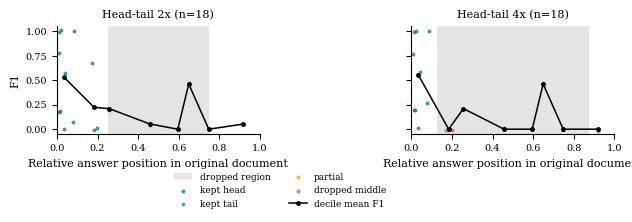

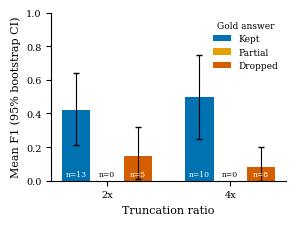

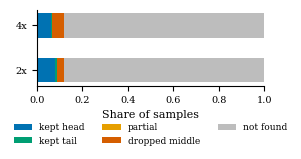

['fig_answer_position_scatter.pdf', 'fig_f1_by_answer_zone.pdf', 'fig_zone_share.pdf']


In [15]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "serif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 6.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
})
COL_W, FULL_W = 3.0, 6.3
ZONE_COLORS = {"kept_head": "#0072B2", "kept_tail": "#009E73",
               "partial": "#E69F00", "dropped_middle": "#D55E00"}

def fig_position_scatter(df, path):
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.5), sharey=True)
    rng = np.random.default_rng(42)
    for ax, r in zip(axes, RATIOS):
        d = df[(df.ratio == r) & df.answer_found]
        keep = 1 / r
        lo, hi = keep * HEAD_FRAC, 1 - keep * (1 - HEAD_FRAC)
        ax.axvspan(lo, hi, color="#d9d9d9", alpha=0.7, lw=0, label="dropped region")
        for z, c in ZONE_COLORS.items():
            s = d[d.answer_zone == z]
            ax.scatter(s.answer_rel_pos, s.f1 + rng.uniform(-0.015, 0.015, len(s)),
                       s=8, c=c, alpha=0.75, lw=0, label=z.replace("_", " "))
        b = pd.cut(d.answer_rel_pos, np.linspace(0, 1, 11), include_lowest=True)
        m = d.groupby(b, observed=True).agg(x=("answer_rel_pos", "mean"), y=("f1", "mean"))
        ax.plot(m.x, m.y, color="k", lw=1.1, marker="o", ms=2.5, label="decile mean F1")
        ax.set_title(f"Head-tail {r}x (n={len(d)})")
        ax.set_xlabel("Relative answer position in original document")
        ax.set_xlim(0, 1); ax.set_ylim(-0.05, 1.05)
    axes[0].set_ylabel("F1")
    axes[0].legend(loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(1.1, -0.28))
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight"); plt.show()

def fig_f1_by_zone(stats, path):
    groups = ["Kept", "Partial", "Dropped"]
    colors = {"Kept": "#0072B2", "Partial": "#E69F00", "Dropped": "#D55E00"}
    fig, ax = plt.subplots(figsize=(COL_W, 2.3))
    w = 0.25
    for gi, g in enumerate(groups):
        for ri, r in enumerate(RATIOS):
            row = stats[(stats.ratio == f"{r}x") & (stats.group == g)].iloc[0]
            x = ri + (gi - 1) * w
            ax.bar(x, row.mean_F1 if row.n else 0, w * 0.92, color=colors[g], label=g if ri == 0 else None)
            if row.n > 1 and not np.isnan(row.CI_low):
                ax.errorbar(x, row.mean_F1, yerr=[[row.mean_F1 - row.CI_low], [row.CI_high - row.mean_F1]],
                            color="k", capsize=2, lw=0.8)
            ax.text(x, 0.015, f"n={int(row.n)}", ha="center", va="bottom", fontsize=5.5, color="white" if row.n else "k")
    ax.set_xticks(range(len(RATIOS))); ax.set_xticklabels([f"{r}x" for r in RATIOS])
    ax.set_xlabel("Truncation ratio"); ax.set_ylabel("Mean F1 (95% bootstrap CI)")
    ax.set_ylim(0, 1); ax.legend(title="Gold answer", frameon=False, title_fontsize=6.5)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.show()

def fig_zone_share(df, path):
    labels = ["kept_head", "kept_tail", "partial", "dropped_middle", "not_found"]
    colors = {**ZONE_COLORS, "not_found": "#bdbdbd"}
    share = (df.groupby("ratio").answer_zone.value_counts(normalize=True)
             .unstack(fill_value=0).reindex(columns=labels, fill_value=0))
    fig, ax = plt.subplots(figsize=(COL_W, 1.9))
    left = np.zeros(len(share))
    for z in labels:
        ax.barh([f"{r}x" for r in share.index], share[z], left=left, color=colors[z],
                label=z.replace("_", " "), height=0.55)
        left += share[z].values
    ax.set_xlim(0, 1); ax.set_xlabel("Share of samples")
    ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.38))
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.show()

fig_position_scatter(pos_df, FIG_DIR / "fig_answer_position_scatter.pdf")
fig_f1_by_zone(stats_df, FIG_DIR / "fig_f1_by_answer_zone.pdf")
fig_zone_share(pos_df, FIG_DIR / "fig_zone_share.pdf")
print(sorted(p.name for p in FIG_DIR.glob("*.pdf")))

## 10. Export tables for LaTeX
Writes `.tex` versions of the summary and statistics tables so they can be pasted into `report/final.tex`.

In [16]:
def to_tex(df, name, **kw):
    try:
        (HERE / name).write_text(df.to_latex(index=False, float_format="%.3f", **kw))
        print("wrote", name)
    except Exception as e:
        print("LaTeX export skipped:", e)

to_tex(summary_df, "part2_summary_table.tex")
to_tex(stats_df, "answer_position_stats.tex")

wrote part2_summary_table.tex
wrote answer_position_stats.tex


## 11. Notes and limitations to disclose in the report
- Truncation is applied to the **document only**; the instruction and question are never truncated, so the prompt-level ratio is lower than the document-level ratio.
- Answer matching is a case-insensitive string search. Abstractive answers cannot be located (`not_found`) and are excluded from the position plots.
- The `dropped_middle` group can be small at 2x; always report `n` and the confidence interval.
- Greedy decoding is not bit-exact across GPUs; a few answers differ between machines.
- The Uncompressed vs Head-tail 2x significance changes between runs, so describe it as a marginal loss.
- If results were produced after a Colab disconnection, they were completed through resume; the per-sample JSONL is the source of truth.